In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import carregar_noaa_por_tipo, carregar_bacias, recorte_top95_global, pareados_por_raio, tabela_ajustes, plotar_mosaico

tipos = carregar_noaa_por_tipo()
pontos = {nome: tipos[nome] for nome in ("Água oceânica", "Areia de praia")}
bacias = recorte_top95_global(carregar_bacias(pontos))
print("Bacias IPBA Top 95% global:", len(bacias), f"(área ≥ {bacias['area_km2'].min():.0f} km²)")

Bacias IPBA Top 95% global: 6002 (área ≥ 638 km²)


In [2]:
pareados = pareados_por_raio(bacias, pontos, raios=(5, 22))
print(tabela_ajustes(pareados).round(3).to_string(index=False))

      Conjunto  R_km  Pop_min                X   N   beta    se  r2_pct  p_value    rho  r2_bins_pct  beta_bins_w
 Água oceânica     5        0 total_population  16  0.754 0.186  54.092    0.001  0.453          NaN          NaN
 Água oceânica     5        0         area_km2  16  0.963 0.380  31.435    0.024 -0.190          NaN          NaN
Areia de praia     5        0 total_population  15  0.203 0.334   2.744    0.555  0.250          NaN          NaN
Areia de praia     5        0         area_km2  15 -0.332 0.543   2.789    0.552 -0.086          NaN          NaN
 Água oceânica    22        0 total_population 160  0.349 0.087   9.315    0.000  0.283       67.104        0.311
 Água oceânica    22        0         area_km2 160 -0.160 0.226   0.315    0.481 -0.165       91.170       -0.697
Areia de praia    22        0 total_population  74  0.077 0.122   0.553    0.529  0.031        0.026       -0.042
Areia de praia    22        0         area_km2  74 -0.045 0.209   0.065    0.829  0.034 

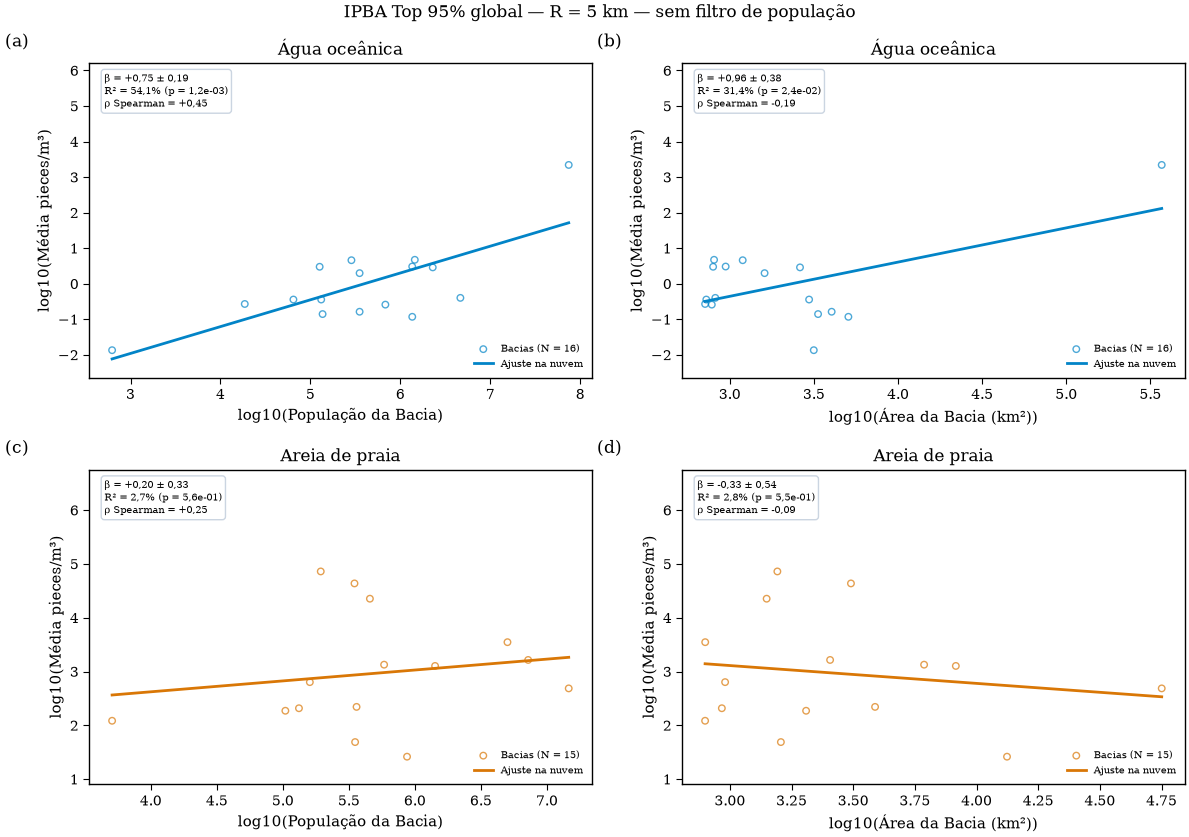

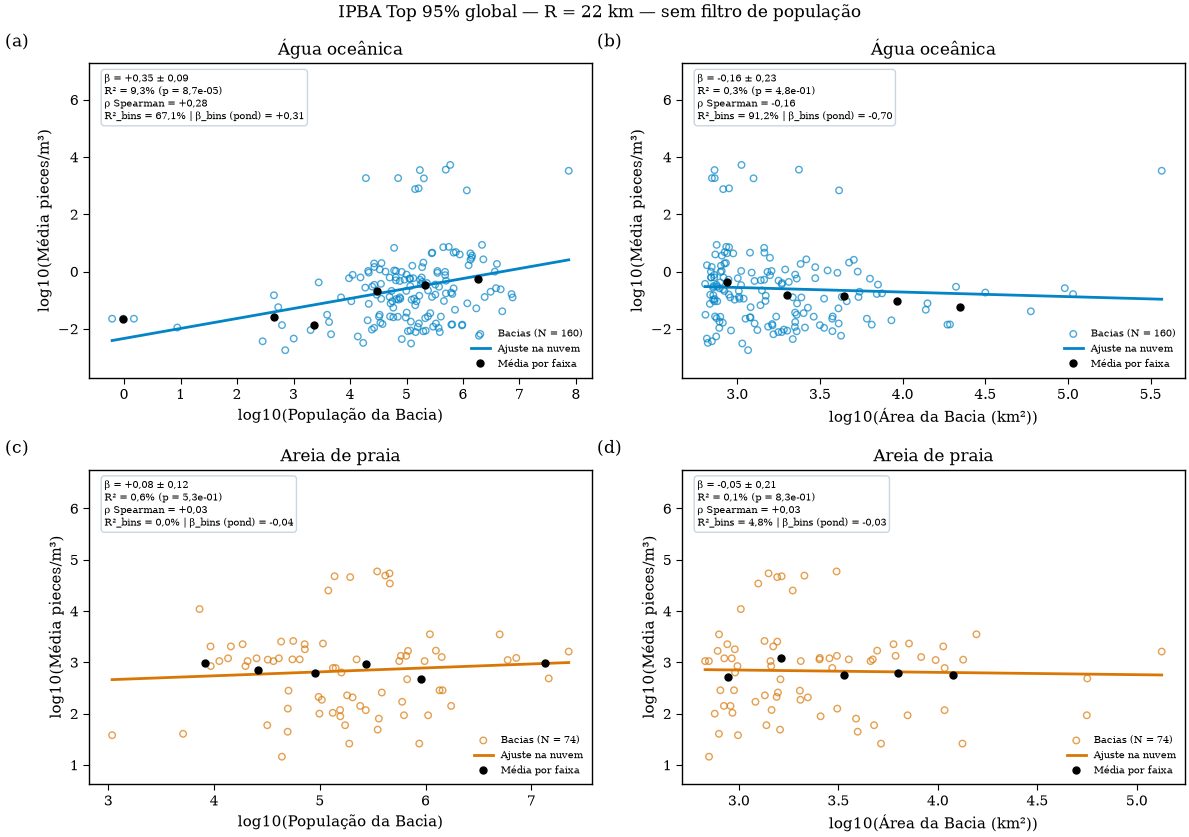

In [3]:
for r in (5, 22):
    plotar_mosaico(pareados[r], f"IPBA Top 95% global — R = {r} km", arquivo=f"mosaico_ipba95_R{r}")